In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path

In [6]:
df = yf.download("NVDA", start="2000-01-01")
df.columns = df.columns.droplevel(1)


[*********************100%***********************]  1 of 1 completed


In [7]:
print(f"SHAPE: {df.shape}")

SHAPE: (6753, 5)


In [8]:
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2000-01-03,0.089206,0.090755,0.084085,0.090041,300912000
2000-01-04,0.086825,0.087897,0.082418,0.087658,300480000
2000-01-05,0.083966,0.085753,0.082775,0.084324,188352000
2000-01-06,0.078487,0.083966,0.075272,0.083966,120480000
2000-01-07,0.079798,0.080631,0.076939,0.078130,71184000


- Open: Giá mở cửa
- High: Giá cao nhất trong phiên giao dịch
- Low: Giá thấp nhất trong phiên giao dịch
- Close: Giá đóng cửa
- Adj Close: Giá đóng cửa hiệu chỉnh (cột qun trong nhất, phản ánh các hành động của công ty)
- Volume: Tổng khối lượng giao dịch

In [13]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6753 entries, 2000-01-03 to 2026-11-06
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6753 non-null   float64
 1   High    6753 non-null   float64
 2   Low     6753 non-null   float64
 3   Open    6753 non-null   float64
 4   Volume  6753 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 316.5 KB


In [ ]:
def time_plot(df):
    # Khởi tạo Figure
    fig = plt.figure(figsize=(14, 10))
    fig.suptitle("Time Plot", fontsize=16)

    gs = fig.add_gridspec(3, 2)

    dates = df.index

    ax_vol = fig.add_subplot(gs[0, :])
    ax_vol.plot(dates, df['Volume'])
    ax_vol.set_title("Volume")

    ax_open = fig.add_subplot(gs[1, 0])
    ax_open.plot(dates, df['Open'])
    ax_open.set_title("Open")

    ax_close = fig.add_subplot(gs[1, 1])
    ax_close.plot(dates, df['Close'])
    ax_close.set_title("Close")

    ax_high = fig.add_subplot(gs[2, 0])
    ax_high.plot(dates, df['High'])
    ax_high.set_title("High")

    ax_low = fig.add_subplot(gs[2, 1])
    ax_low.plot(dates, df['Low'])
    ax_low.set_title("Low")

    plt.tight_layout(pad=3.0, h_pad=2.5, w_pad=2.0)
    plt.show()

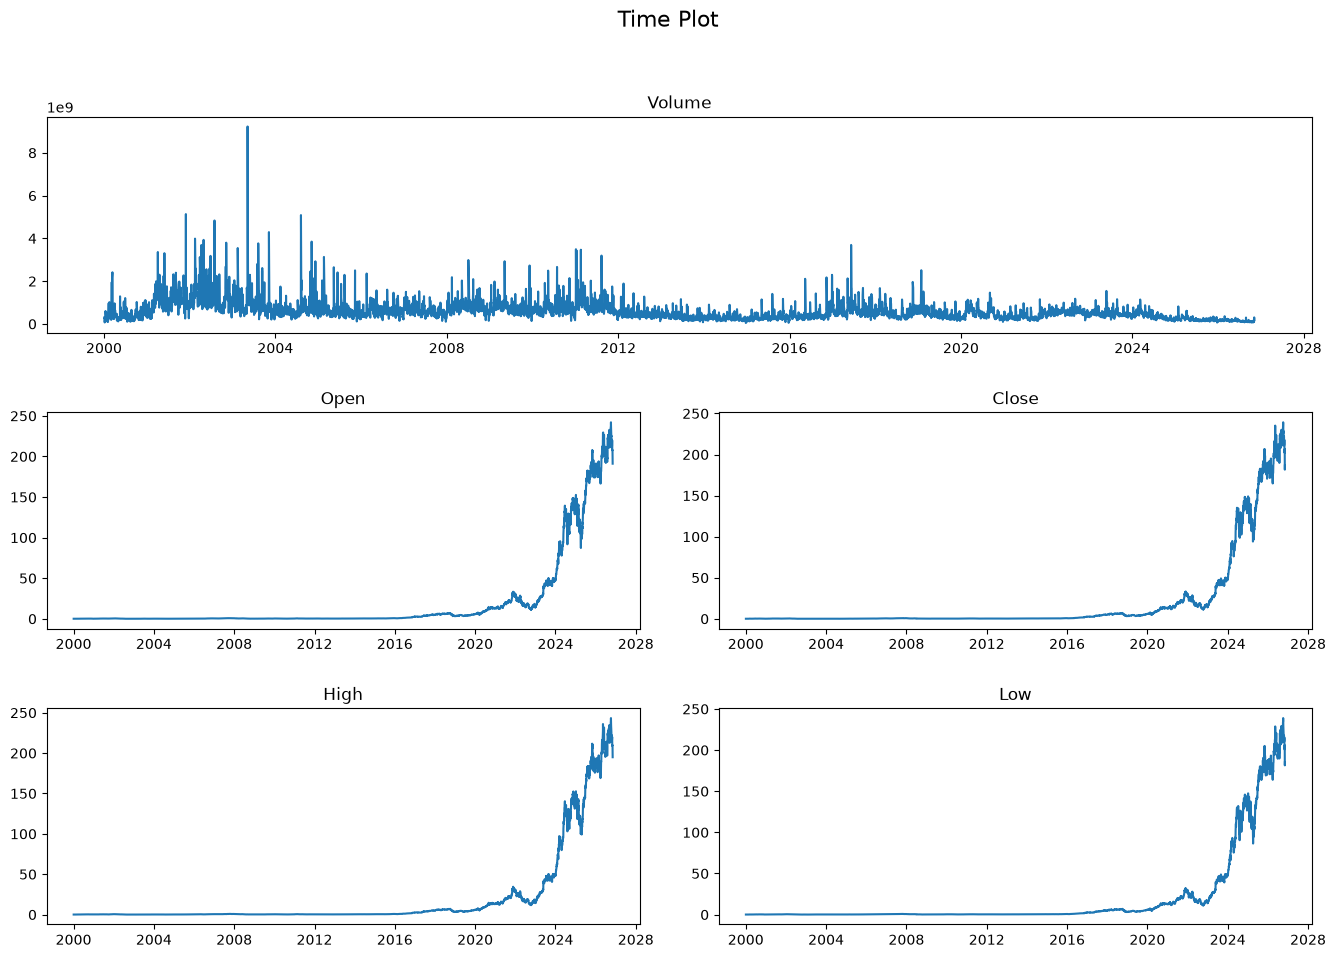

In [25]:
time_plot(df)

### Nhận xét về xu hướng (Trend)

- Giá cổ phiếu có xu hướng tăng mạnh trong dài hạn.
- Điều này cho thấy giá cổ phiếu nhìn chung tăng theo thời gian.

### Nhận xét về tính mùa vụ (Seasonality)

- Không có dấu hiệu rõ ràng về tính mùa vụ trong dài hạn.
- Biến động giá chủ yếu phụ thuộc vào điều kiện thị trường thay vì tuân theo các chu kỳ mùa vụ cố định.

### Nhận xét về nhiễu (Noise)

- Nhiễu thể hiện rõ qua những biến động giá hằng ngày, với đường biểu diễn giá xuất hiện nhiều dao động liên tục.
- Biểu đồ khối lượng giao dịch (Volume) chịu ảnh hưởng chủ yếu bởi nhiễu, thể hiện qua các đợt tăng đột biến ngẫu nhiên và khó dự đoán, đặc biệt đối với cổ phiếu NVDA.
- Những biến động về khối lượng giao dịch này không cho thấy xu hướng rõ ràng.

In [27]:
# Thực hiện các thao tác trên 1 cột này.
df_close_serires = pd.Series(df['Close'])

In [ ]:
def calc_max_lag(series: pd.Series) -> int:
    n = series.count()
    max_lag = int(min(10 * np.log10(n), n / 5)) if n > 0 else 0

    return max_lag

 Lag: 38


### ACF (Autocorrelation Function)

- Đo lường mức độ tương quan tuyến tính giữa một chuỗi thời gian \(Y_t\) và chính nó tại thời điểm trễ \(k\) bước trong quá khứ (\(Y_{t-k}\).
- ACF cho biết mức độ tương quan giữa giá trị hiện tại và các giá trị trong quá khứ tại từng độ trễ (*lag*).

**Ý nghĩa:** Cho biết giá trị hiện tại có mối tương quan mạnh hay yếu với các giá trị trong quá khứ.

In [ ]:
# Cov/Var
def calc_acf(X: pd.Series, max_lag: int) -> np.array:
    n = len(X)

    mean = np.mean(X)
    var = np.var(X)

    X_centered = X - mean

    acf_values = [1.0]

    for k in range(1, max_lag + 1):

        cov = np.sum(X_centered[k:] * X_centered[:-k]) / n

        acf_values.append(cov/var)

    return np.array(acf_values)


[1.         0.99823944 0.99658229 0.99452928 0.99232583 0.99022911
 0.98807326 0.98570408 0.98329306 0.9808191  0.97839293 0.97608869
 0.97375451 0.97117981 0.96874212 0.96628916 0.96390858 0.96145216
 0.95889433 0.95615151 0.95346575 0.95070309 0.94790894 0.94492779
 0.94189832 0.93887815 0.93599194 0.93318779 0.93044868 0.92773997
 0.92498838 0.92233486 0.91969389 0.9170291  0.91427729 0.91156425
 0.90898207 0.90647346 0.90409856]


### PACF (Partial Autocorrelation Function)
- Đo lường mối tương quan giữa Yt và Yt-k nhưng loại bỏ ảnh hưởng  của các bước trung gian giữa t và t - k

In [ ]:
# thuật toán Dubrin-Levinson
def calc_pacf(X: pd.Series, max_lag: int, acf: None) -> np.array:

    acf = calc_acf(X, max_lag) if acf is None else acf
    
    pacf = np.zeros(max_lag + 1)
    pacf[0] = 1.0

    if max_lag == 0:
        return pacf

    phi = np.zeros((max_lag + 1, max_lag + 1))

    phi[1, 1] = acf[1]
    pacf[1] = phi[1, 1]

    for k in range(2, max_lag + 1):
        
        num = acf[k] - np.sum(phi[k-1, 1:k] * acf[k-1:0:-1])
        den = 1.0 - np.sum(phi[k-1, 1:k] * acf[1:k])

        phi[k, k] = num / den
        pacf[k] = phi [k, k]

        for j in range(1, k):
            phi[k, j] = phi[k-1, j] - phi[k, k] * phi[k-1, k-j]

    return pacf


[ 1.          0.99823944  0.0285139  -0.11258292 -0.05069266  0.03974211
 -0.00538605 -0.06963686 -0.01801848 -0.00256424  0.02025032  0.03384313
 -0.01073431 -0.07815598  0.03675134  0.01975502  0.01392996 -0.03902321
 -0.03397852 -0.04293937  0.02398025 -0.00984853 -0.02231554 -0.06138975
 -0.00237461  0.02915612  0.04078076  0.01524027  0.00202571  0.01131341
 -0.00491643  0.02824082 -0.01111784 -0.02330456 -0.03331534  0.02755435
  0.05048093  0.01564932  0.01504675]


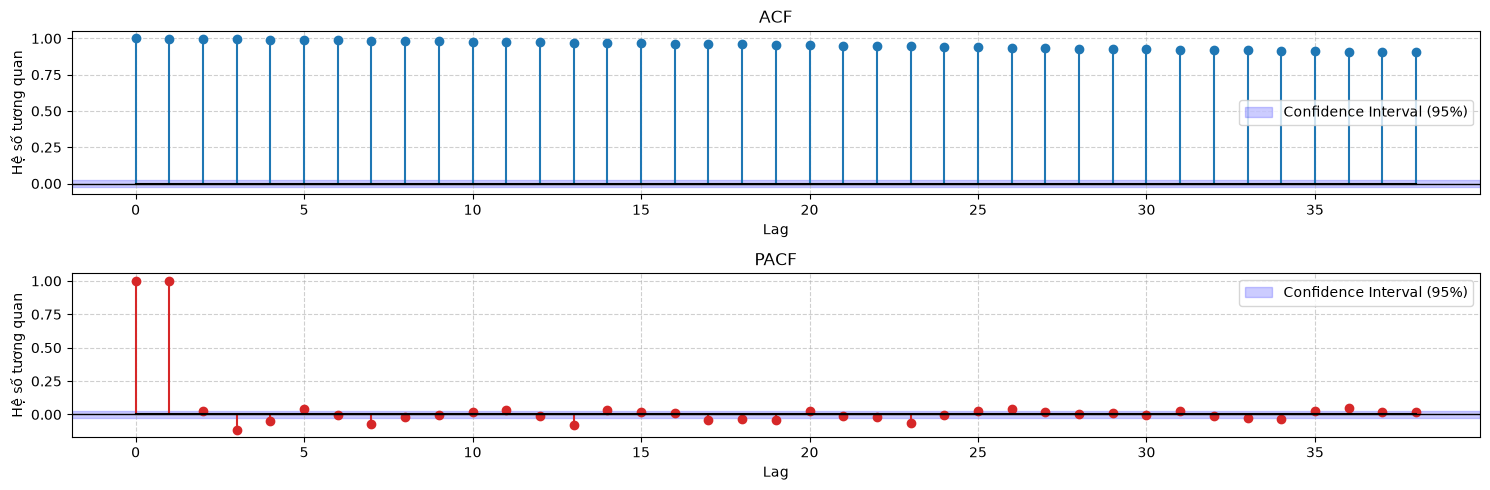

In [ ]:
def plot_acf_and_pacf(acf_vals, pacf_vals, n):
    
    lag = len(acf_vals)
    lag_idx = np.arange(lag)

    # Khoảng tin cậy 95% -> 1.96 / căn(N)
    conf_interval = 1.96 / np.sqrt(n)

    fig, axes = plt.subplots(nrows=2, ncols=1, figsize = (15, 5))
    fig.subplots_adjust(hspace=0.05)

    # ACF
    axes[0].stem(lag_idx, acf_vals, basefmt='k-', linefmt='C0-', markerfmt='C0o')

    axes[0].axhspan(-conf_interval, conf_interval, alpha=0.2, color='blue',
                     label="Confidence Interval (95%)")
    axes[0].axhline(y=0, color='k', linestyle='-', linewidth=1)

    axes[0].set_title("ACF")
    axes[0].set_xlabel("Lag")
    axes[0].set_ylabel("Hệ số tương quan")
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()

    # PACF
    axes[1].stem(lag_idx, pacf_vals, basefmt='k-', linefmt='C3-', markerfmt='C3o')
    axes[1].axhspan(-conf_interval, conf_interval, alpha=0.2, color='blue',
                         label="Confidence Interval (95%)")
    axes[1].axhline(y=0, color='k', linestyle='-', linewidth=1)

    axes[1].set_title("PACF")
    axes[1].set_xlabel("Lag")
    axes[1].set_ylabel("Hệ số tương quan")
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [54]:
def init_acf_pacf(series: pd.Series):
    n = len(series)
    max_lag = calc_max_lag(series)

    print(f"Số lượng quan sát (n): {n}")
    print(f"Max Lag áp dụng: {max_lag}")

    acf = calc_acf(series, max_lag)
    pacf = calc_pacf(series, max_lag)

    plot_acf_and_pacf(acf, pacf, n)

Số lượng quan sát (n): 6753
Max Lag áp dụng: 38


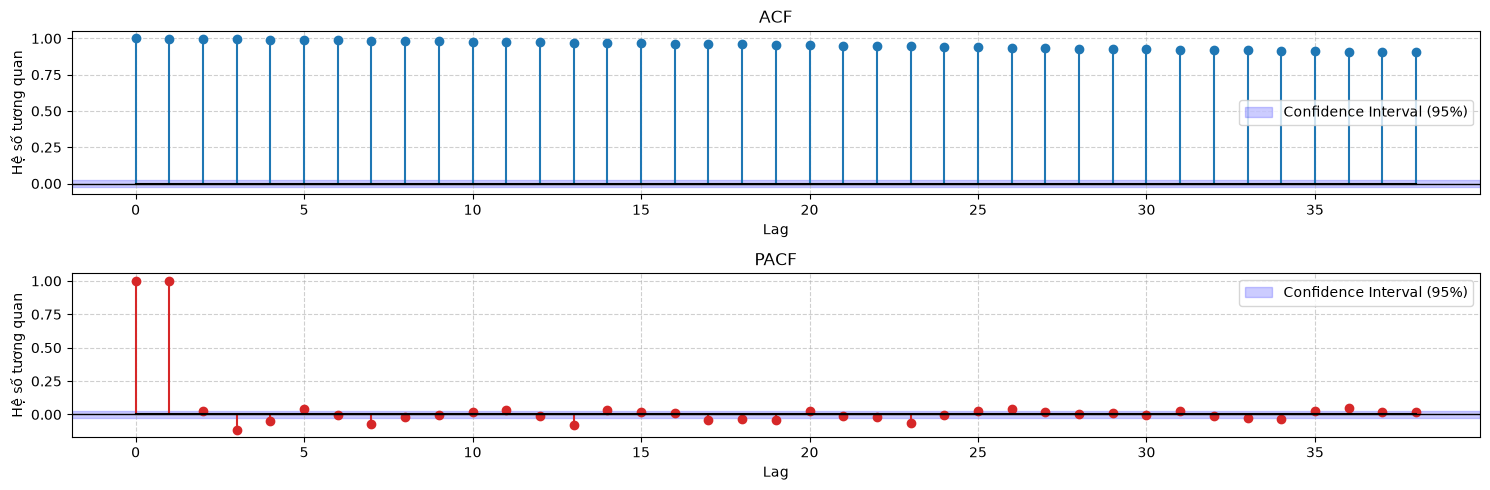

In [55]:
init_acf_pacf(df_close_serires)

### Đánh giá biểu đồ ACF

- ACF giảm cực kỳ chậm và vẫn duy trì mức tương quan rất cao xuyên suốt 38 lags.
- Điều này cho thấy các giá trị trong quá khứ vẫn có mối tương quan mạnh với giá trị hiện tại, tức ảnh hưởng của quá khứ vẫn được duy trì trong thời gian dài.

### Đánh giá biểu đồ PACF

- Có một cột tại lag 1 đạt giá trị gần bằng 1.0.
- Sau đó, giá trị PACF lập tức giảm xuống gần bằng 0.
- Các lag tiếp theo đều có giá trị tương đối thấp và nằm trong dải tin cậy (*confidence interval*).

### Tổng kết

=> Đây là dấu hiệu điển hình gợi ý mô hình **Random Walk (Bước ngẫu nhiên)**, trong đó giá trị hiện tại được xác định bằng giá trị ở thời điểm trước đó cộng với một thành phần nhiễu ngẫu nhiên (*random noise*).


In [64]:
def rolling_stat(series:pd.Series, window_sizes: list = [7, 30, 90]):

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex='all')

    axes[0].plot(series.index, series, label='Origin', color='lightgray', alpha=0.6)
    for w in window_sizes:
        rolling_mean = series.rolling(window=w).mean()
        axes[0].plot(series.index, rolling_mean, label=f'Rolling Mean {w}D')

    axes[0].set_title('Rolling Mean')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    for w in window_sizes:
        rolling_std = series.rolling(window=w).std()
        axes[1].plot(series.index, rolling_std, label=f'Rolling Std {w}D')

    axes[1].set_title('Rolling Standard Deviation')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
        

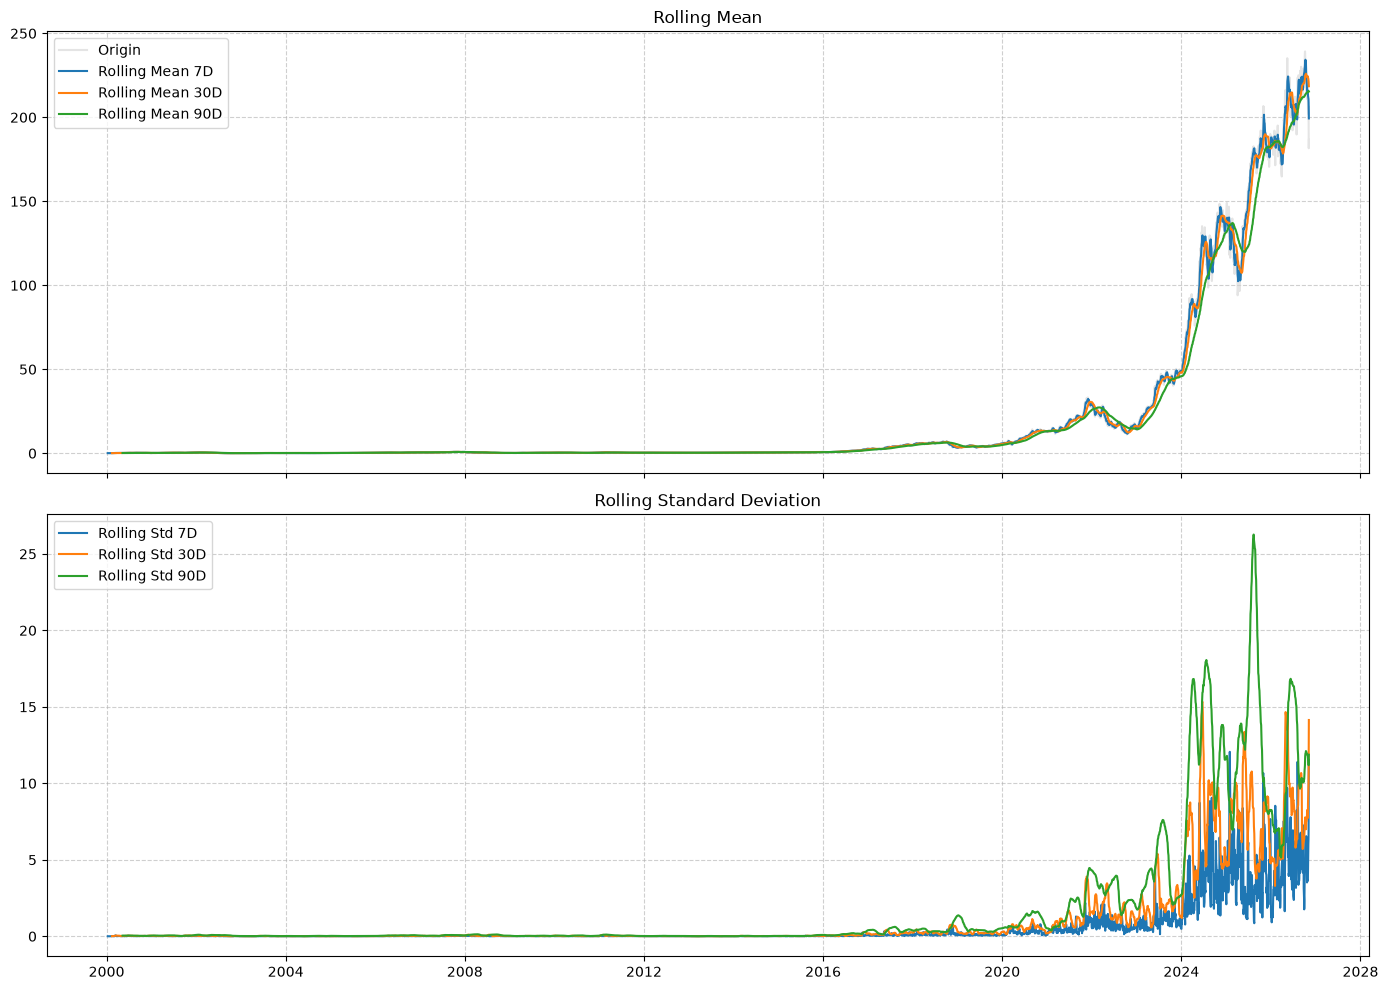

In [65]:
rolling_stat(df_close_serires)

- Window size càng lớn thì đường biểu diễn càng mượt (*smooth*), ít dao động gắt và triệt tiêu được nhiều nhiễu (*noise*) ngắn hạn hơn.

### Đánh giá Rolling Mean

- Window size 90 gần như luôn có giá trị thấp nhất, tiếp đến là 30 và cuối cùng là 7.
- Window size 7 cho thấy khả năng bám sát giá thực tế tốt hơn, đồng thời thể hiện rõ các biến động ngắn hạn thông qua những cú giật.
- Trong khi đó, window size càng lớn thì mức độ phản ứng với giá hiện tại càng chậm.
- Cả 3 window size đều cho thấy xu hướng tăng của chuỗi thời gian.

**Kết luận:** Các đường Rolling Mean không dao động quanh một mốc cố định mà có xu hướng tăng mạnh về cuối giai đoạn.

### Đánh giá Rolling Std

- Window size 7 thể hiện sự biến động ngắn hạn rõ nhất, tiếp đến là 30 và 90.
- Window size 90 có xu hướng duy trì quán tính, có thể quan sát rõ trong giai đoạn 2024–2028.
- Đường Rolling Std 90D cũng đạt giá trị tuyệt đối cao nhất.

**Kết luận:** Ở giai đoạn đầu, độ lệch chuẩn gần như nằm sát mốc 0. Tuy nhiên, về những năm cuối, biên độ dao động phình to đáng kể.

### Tổng kết

=> Chuỗi thời gian thể hiện tính không dừng (*non-stationary*) rõ rệt, với hai đặc điểm chính:
- **Mean không ổn định:** Xuất hiện xu hướng tăng (*trend*).
- **Variance không ổn định:** Phương sai có xu hướng tăng và biên độ dao động ngày càng mở rộng.

### Kết luận
- Phải thực hiện tiền xử lí trước khi thực hiện các thao tác phực tạp sau

In [66]:
# Dùng phân phối dều (Uniform Distribution)

def fault_injection(series: pd.Series, missing_rate: float = 0.5):
    se_fault = series.copy()

    np.random.seed(42)

    n_missing = int(len(series) * missing_rate)

    # Ngẫu nhiên ko hoàn lại
    missing_indices = np.random.choice(series.index, size=n_missing, replace=False)

    se_fault.loc[missing_indices] = np.nan

    print(f"Tỉ lệ khuyết thực tế{se_fault.isna().mean(): .2%}")

    return se_fault

In [67]:
se_fault = fault_injection(df_close_serires)

Tỉ lệ khuyết thực tế 49.99%


In [69]:
# Forward Fill
se_ff = se_fault.ffill()

# Linear Interpolation
se_p1 = se_fault.interpolate(method='polynomial', order=1)

# Quadratic Interpolation
se_p2 = se_fault.interpolate(method='polynomial', order=2)

# Cubic Interpolation
se_p3 = se_fault.interpolate(method='polynomial', order=3)

# Spline
se_spline = se_fault.interpolate(method='spline', order=3)

In [72]:
def calc_mae(y_true: pd.Series, y_pred: pd.Series):

    return (y_true - y_pred).abs().mean()

def calc_rmse(y_true: pd.Series, y_pred: pd.Series):
    return np.sqrt(((y_true - y_pred) ** 2).mean())

In [ ]:
# TÍnh MAE và RMSE cho từng phương pháp điền khuyết
ff_mae, ff_rmse = calc_mae(df_close_serires, se_ff), calc_rmse(df_close_serires, se_ff)

p1_mae, p1_rmse = calc_mae(df_close_serires, se_p1), calc_rmse(df_close_serires, se_p1)

p2_mae, p2_rmse = calc_mae(df_close_serires, se_p2), calc_rmse(df_close_serires, se_p2)

p3_mae, p3_rmse = calc_mae(df_close_serires, se_p3), calc_rmse(df_close_serires, se_p3)

spline_mae, spline_rmse = calc_mae(df_close_serires, se_spline), calc_rmse(df_close_serires, se_spline)